In [1]:
import pandas as pd
import numpy as np
import joblib
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
import os



In [2]:
X_train_full = pd.read_csv("../processed/X_train.csv")
y_train_full = pd.read_csv("../processed/y_train.csv").squeeze("columns")

# Load engine IDs
engine_ids = pd.read_csv("../processed/train_engine_ids.csv")["engine_id"]

# Load feature names
feature_columns = joblib.load(
    "../processed/feature_columns.pkl"
)

print("Input shape:", X_train_full.shape)
print("Target shape:", y_train_full.shape)
print("Engine IDs:", engine_ids.nunique())
print("Features:", len(feature_columns))

Input shape: (20631, 18)
Target shape: (20631,)
Engine IDs: 100
Features: 18


In [3]:
# Create group-based splitter
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

# Generate training and validation indices
train_idx, val_idx = next(
    gss.split(X_train_full, y_train_full, groups=engine_ids)
)

# Split input features
X_train = X_train_full.iloc[train_idx]
X_val = X_train_full.iloc[val_idx]

# Split target values
y_train = y_train_full.iloc[train_idx]
y_val = y_train_full.iloc[val_idx]

# Split engine IDs
train_engine_ids = engine_ids.iloc[train_idx]
val_engine_ids = engine_ids.iloc[val_idx]

In [4]:
print("Training input:", X_train.shape)
print("Validation input:", X_val.shape)

print("\nTraining target:", y_train.shape)
print("Validation target:", y_val.shape)

print("\nTraining engines:", train_engine_ids.nunique())
print("Validation engines:", val_engine_ids.nunique())

print("\nCommon engines:",
      len(set(train_engine_ids) & set(val_engine_ids)))

Training input: (16561, 18)
Validation input: (4070, 18)

Training target: (16561,)
Validation target: (4070,)

Training engines: 80
Validation engines: 20

Common engines: 0


In [5]:
#scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_val_scaled = scaler.transform(X_val)

print("Training scaled shape:", X_train_scaled.shape)
print("Validation scaled shape:", X_val_scaled.shape)

print("\nTraining feature means:")
print(np.round(X_train_scaled.mean(axis=0), 3))

print("\nTraining feature standard deviations:")
print(np.round(X_train_scaled.std(axis=0), 3))

Training scaled shape: (16561, 18)
Validation scaled shape: (4070, 18)

Training feature means:
[ 0. -0.  0. -0.  0. -0. -0. -0. -0. -0. -0.  0.  0.  0.  0. -0.  0.  0.]

Training feature standard deviations:
[1. 1. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [6]:
print("Unique setting_3 values in training:")
print(X_train_full["setting_3"].unique())

print("Unique setting_3 values in training:")
print(X_train_full["setting_3"].unique())

Unique setting_3 values in training:
[100.]
Unique setting_3 values in training:
[100.]


In [7]:
# Remove setting_3 from input features
feature_columns.remove("setting_3")

# Update training and validation datasets
X_train = X_train[feature_columns]
X_val = X_val[feature_columns]

# Create a fresh scaler
scaler = StandardScaler()

# Fit only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform validation data
X_val_scaled = scaler.transform(X_val)

print("Number of features:", len(feature_columns))
print("Training shape:", X_train_scaled.shape)
print("Validation shape:", X_val_scaled.shape)

Number of features: 17
Training shape: (16561, 17)
Validation shape: (4070, 17)


In [8]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/attr_value.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/tensor.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framewo

TensorFlow version: 2.20.0


In [9]:
from tensorflow import keras
from tensorflow.keras import layers


In [10]:
model = keras.Sequential([

    # Input layer
    layers.Input(shape=(17,)),

    # Hidden layer 1
    layers.Dense(64, activation="relu"), 

    # Hidden layer 2
    layers.Dense(32, activation="relu"), 

    # Hidden layer 3
    layers.Dense(16, activation="relu"),

    # Output layer
    layers.Dense(1, activation="linear") 

])

In [11]:
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,777 (14.75 KB)

 Trainable params: 3,777 (14.75 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
model.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=[
        keras.metrics.MeanAbsoluteError(name="mae"),
        keras.metrics.RootMeanSquaredError(name="rmse")
    ]
)
print("Model compiled successfully!")

Model compiled successfully!


In [13]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 3785.4985 - mae: 48.3348 - rmse: 61.5264 - val_loss: 673.0583 - val_mae: 21.1753 - val_rmse: 25.9434
Epoch 2/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 596.2933 - mae: 19.6497 - rmse: 24.4191 - val_loss: 439.2838 - val_mae: 16.8184 - val_rmse: 20.9591
Epoch 3/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 432.6397 - mae: 16.2845 - rmse: 20.8000 - val_loss: 339.3680 - val_mae: 14.0996 - val_rmse: 18.4219
Epoch 4/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 382.5278 - mae: 14.9741 - rmse: 19.5583 - val_loss: 326.3479 - val_mae: 13.8915 - val_rmse: 18.0651
Epoch 5/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 368.2480 - mae: 14.5966 - rmse: 19.1898 - val_loss: 317.8915 - val_mae: 13.4056 - val_rmse: 17.8295
Epoch 6/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 359.0759 - mae: 14.2806 - rmse: 18.9493 - val_loss: 309.2496 - val_mae: 13.3040 - val_rmse: 17.5855
Epoch 7/100
259/259 ━━━━━━━━━━━━━

In [14]:
print("Epochs completed:", len(history.history["loss"]))

best_epoch = np.argmin(history.history["val_loss"]) + 1

print("Best epoch:", best_epoch)
print("Best validation loss:", min(history.history["val_loss"]))

Epochs completed: 39
Best epoch: 29
Best validation loss: 277.91802978515625


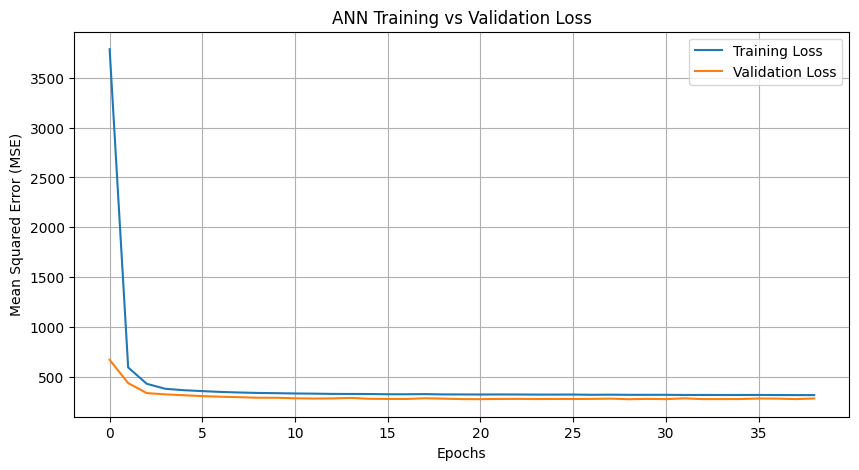

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("ANN Training vs Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

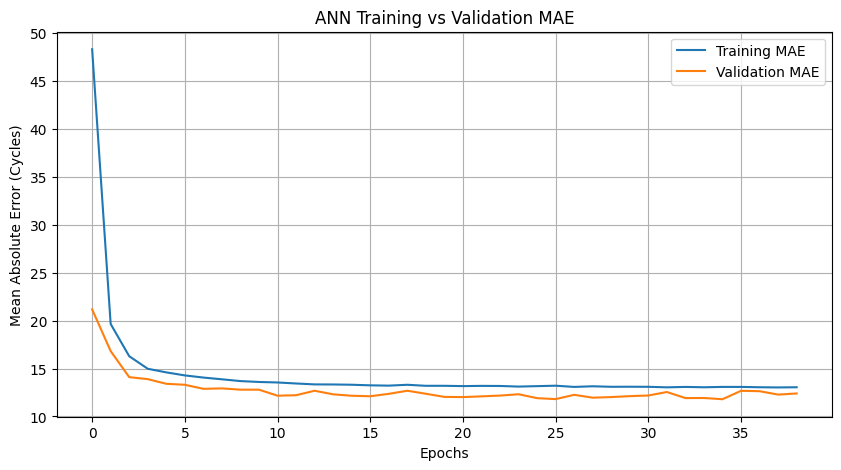

In [16]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["mae"], label="Training MAE")
plt.plot(history.history["val_mae"], label="Validation MAE")

plt.xlabel("Epochs")
plt.ylabel("Mean Absolute Error (Cycles)")
plt.title("ANN Training vs Validation MAE")

plt.legend()
plt.grid(True)
plt.show()

In [17]:
mae_results = pd.DataFrame({
    "Epoch": range(1, len(history.history["mae"]) + 1),
    "Training_MAE": history.history["mae"],
    "Validation_MAE": history.history["val_mae"]
})

print(mae_results.round(2).to_string(index=False))

best_mae_epoch = mae_results["Validation_MAE"].idxmin()

print("Best Validation MAE:", round(
    mae_results.loc[best_mae_epoch, "Validation_MAE"], 2
))

print("Epoch with Best Validation MAE:",
      mae_results.loc[best_mae_epoch, "Epoch"])

 Epoch  Training_MAE  Validation_MAE
     1         48.33           21.18
     2         19.65           16.82
     3         16.28           14.10
     4         14.97           13.89
     5         14.60           13.41
     6         14.28           13.30
     7         14.06           12.88
     8         13.87           12.92
     9         13.69           12.79
    10         13.60           12.79
    11         13.54           12.16
    12         13.44           12.21
    13         13.34           12.68
    14         13.33           12.30
    15         13.31           12.16
    16         13.24           12.10
    17         13.21           12.36
    18         13.30           12.68
    19         13.20           12.37
    20         13.20           12.04
    21         13.16           12.02
    22         13.19           12.09
    23         13.18           12.18
    24         13.11           12.31
    25         13.16           11.91
    26         13.21           11.81
 

In [18]:
val_loss, val_mae, val_rmse = model.evaluate(
    X_val_scaled,
    y_val,
    verbose=0
)

print("Validation Performance")
print("----------------------")
print("MSE :", round(val_loss, 2))
print("MAE :", round(val_mae, 2))
print("RMSE:", round(val_rmse, 2))

Validation Performance
----------------------
MSE : 277.92
MAE : 12.02
RMSE: 16.67


In [19]:
y_val_pred = model.predict(X_val_scaled).flatten()

comparison = pd.DataFrame({
    "Actual_RUL": y_val.values,
    "Predicted_RUL": y_val_pred
})

comparison["Error"] = (
    comparison["Actual_RUL"] - comparison["Predicted_RUL"]
)

print(comparison.head(10).round(2))

128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
   Actual_RUL  Predicted_RUL  Error
0         125     120.190002   4.81
1         125     118.959999   6.04
2         125     122.370003   2.63
3         125     119.519997   5.48
4         125     119.099998   5.90
5         125     123.940002   1.06
6         125     119.180000   5.82
7         125     126.589996  -1.59
8         125     122.510002   2.49
9         125     127.080002  -2.08


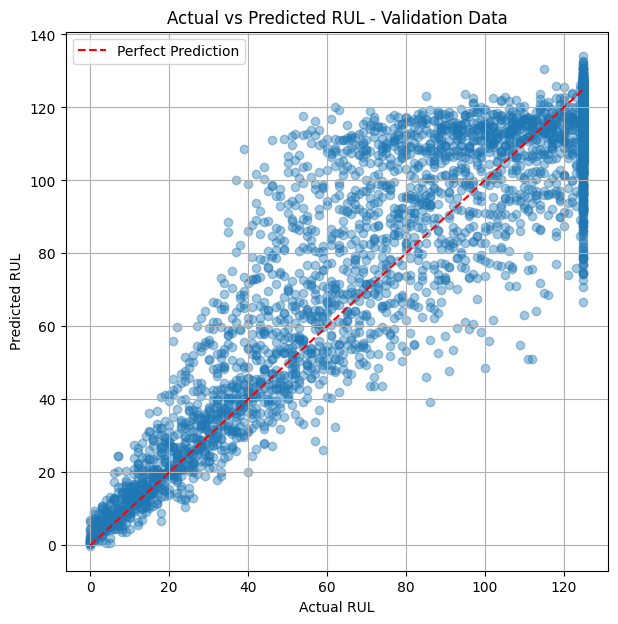

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 7))

plt.scatter(
    y_val,
    y_val_pred,
    alpha=0.4
)

plt.plot(
    [0, 125],
    [0, 125],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("Actual vs Predicted RUL - Validation Data")
plt.legend()
plt.grid(True)
plt.show()

In [21]:
comparison["Absolute_Error"] = comparison["Error"].abs()

worst_predictions = comparison.sort_values(
    "Absolute_Error",
    ascending=False
)

print(worst_predictions.head(10).round(2))

      Actual_RUL  Predicted_RUL  Error  Absolute_Error
3003          39     108.580002 -69.58           69.58
145           46     111.040001 -65.04           65.04
137           54     117.779999 -63.78           63.78
3005          37     100.070000 -63.07           63.07
142           49     111.370003 -62.37           62.37
1372          51     112.139999 -61.14           61.14
3822         112      51.040001  60.96           60.96
139           52     112.709999 -60.71           60.71
3823         111      51.070000  59.93           59.93
1381          42     101.790001 -59.79           59.79


In [22]:
X_test_full = pd.read_csv("../processed/X_test.csv")

y_test_full = pd.read_csv(
    "../processed/y_test.csv"
).squeeze("columns")

print("Test input shape:", X_test_full.shape)
print("Test target shape:", y_test_full.shape)

Test input shape: (13096, 18)
Test target shape: (13096,)


In [23]:
print("Unique setting_3 values in test data:")
print(X_test_full["setting_3"].unique())

Unique setting_3 values in test data:
[100.]


In [24]:
# Select the same 17 features used during training
X_test = X_test_full[feature_columns]

# Apply the already-fitted training scaler
X_test_scaled = scaler.transform(X_test)

print("Selected test features:", len(feature_columns))
print("Test data shape:", X_test.shape)
print("Scaled test data shape:", X_test_scaled.shape)

Selected test features: 17
Test data shape: (13096, 17)
Scaled test data shape: (13096, 17)


In [25]:
# Generate predictions for all test records
y_test_pred = model.predict(X_test_scaled).flatten()

print("Prediction shape:", y_test_pred.shape)
print("\nFirst 10 predictions:")
print(np.round(y_test_pred[:10], 2))

410/410 ━━━━━━━━━━━━━━━━━━━━ 0s 584us/step
Prediction shape: (13096,)

First 10 predictions:
[122.98 119.23 118.16 119.   123.89 123.11 118.03 120.6  125.59 121.42]


In [26]:
test_columns = [
    "engine_id",
    "cycle",
    "setting_1",
    "setting_2",
    "setting_3"
] + [f"sensor_{i}" for i in range(1, 22)]

test_metadata = pd.read_csv(
    "../dataset/test_FD001.txt",
    sep=r"\s+",
    header=None,
    names=test_columns
)

print("Metadata shape:", test_metadata.shape)
print("Number of test engines:", test_metadata["engine_id"].nunique())
print("Rows aligned:", len(test_metadata) == len(X_test_full))

Metadata shape: (13096, 26)
Number of test engines: 100
Rows aligned: True


In [27]:
# Find the index of the final cycle for each engine
final_idx = (
    test_metadata.groupby("engine_id")["cycle"]
    .idxmax()
    .sort_values()
)

# Extract final actual RUL values
y_test_final = y_test_full.iloc[final_idx].to_numpy()

# Extract final predictions
y_test_pred_final = y_test_pred[final_idx.to_numpy()]

# Store engine information
test_final_info = test_metadata.loc[
    final_idx, ["engine_id", "cycle"]
].reset_index(drop=True)

print("Final test engines:", len(final_idx))
print("Actual RUL shape:", y_test_final.shape)
print("Predicted RUL shape:", y_test_pred_final.shape)

Final test engines: 100
Actual RUL shape: (100,)
Predicted RUL shape: (100,)


In [28]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Calculate evaluation metrics
test_mae = mean_absolute_error(
    y_test_final, y_test_pred_final
)

test_mse = mean_squared_error(
    y_test_final, y_test_pred_final
)

test_rmse = np.sqrt(test_mse)

test_r2 = r2_score(
    y_test_final, y_test_pred_final
)

print("NASA Official Test Performance")
print("------------------------------")
print("MAE :", round(test_mae, 2))
print("MSE :", round(test_mse, 2))
print("RMSE:", round(test_rmse, 2))
print("R2  :", round(test_r2, 4))

NASA Official Test Performance
------------------------------
MAE : 11.86
MSE : 282.94
RMSE: 16.82
R2  : 0.8238


In [29]:
test_comparison = pd.DataFrame({
    "Engine_ID": test_final_info["engine_id"],
    "Final_Cycle": test_final_info["cycle"],
    "Actual_RUL": y_test_final,
    "Predicted_RUL": y_test_pred_final
})

test_comparison["Error"] = (
    test_comparison["Actual_RUL"]
    - test_comparison["Predicted_RUL"]
)

test_comparison["Absolute_Error"] = (
    test_comparison["Error"].abs()
)

# Display 10 largest prediction errors
worst_test_predictions = test_comparison.sort_values(
    "Absolute_Error",
    ascending=False
)

print(worst_test_predictions.head(10).round(2))

    Engine_ID  Final_Cycle  Actual_RUL  Predicted_RUL  Error  Absolute_Error
78         79          101          63     112.849998 -49.85           49.85
40         41          123          18      67.800003 -49.80           49.80
26         27          140          66     113.669998 -47.67           47.67
11         12          217         124      77.800003  46.20           46.20
44         45          152         114      70.480003  43.52           43.52
92         93          244          85      46.049999  38.95           38.95
36         37          121          21      56.990002 -35.99           35.99
66         67           71          77     110.739998 -33.74           33.74
14         15           76          83     115.989998 -32.99           32.99
17         18          133          28      58.139999 -30.14           30.14


In [30]:
error_thresholds = [10, 20, 30, 40, 50]

for threshold in error_thresholds:
    count = (
        test_comparison["Absolute_Error"] > threshold
    ).sum()

    print(
        f"Errors above {threshold} cycles: "
        f"{count}/100 engines"
    )

print("\nMean prediction error:", round(
    test_comparison["Error"].mean(), 2
))

print("Maximum absolute error:", round(
    test_comparison["Absolute_Error"].max(), 2
))

Errors above 10 cycles: 40/100 engines
Errors above 20 cycles: 20/100 engines
Errors above 30 cycles: 10/100 engines
Errors above 40 cycles: 5/100 engines
Errors above 50 cycles: 0/100 engines

Mean prediction error: -3.91
Maximum absolute error: 49.85


In [31]:
# Calculate validation errors
comparison["Absolute_Error"] = comparison["Error"].abs()

# Overall error statistics
print("VALIDATION ERROR ANALYSIS")
print("-------------------------")

print("Mean Error:",
      round(comparison["Error"].mean(), 2))

print("Median Error:",
      round(comparison["Error"].median(), 2))

print("Mean Absolute Error:",
      round(comparison["Absolute_Error"].mean(), 2))

print("Maximum Absolute Error:",
      round(comparison["Absolute_Error"].max(), 2))

# Overestimation and underestimation
overestimated = (comparison["Error"] < 0).sum()
underestimated = (comparison["Error"] > 0).sum()
exact = (comparison["Error"] == 0).sum()

print("\nOverestimated:", overestimated)
print("Underestimated:", underestimated)
print("Exact predictions:", exact)

VALIDATION ERROR ANALYSIS
-------------------------
Mean Error: -0.08
Median Error: 1.83
Mean Absolute Error: 12.02
Maximum Absolute Error: 69.58

Overestimated: 1755
Underestimated: 2315
Exact predictions: 0


In [32]:
# Create RUL ranges using the existing comparison DataFrame
comparison["RUL_Range"] = pd.cut(
    comparison["Actual_RUL"],
    bins=[-1, 25, 50, 75, 100, 125],
    labels=["0-25", "26-50", "51-75", "76-100", "101-125"]
)

# Calculate performance for each range
rul_analysis = comparison.groupby(
    "RUL_Range",
    observed=False
).agg(
    Engine_Records=("Actual_RUL", "count"),
    MAE=("Absolute_Error", "mean"),
    Mean_Error=("Error", "mean")
).round(2)

print("VALIDATION PERFORMANCE BY RUL RANGE")
print("------------------------------------")
print(rul_analysis)

VALIDATION PERFORMANCE BY RUL RANGE
------------------------------------
           Engine_Records    MAE  Mean_Error
RUL_Range                                   
0-25                  520   5.09       -3.56
26-50                 500  13.65       -9.96
51-75                 500  20.02      -14.04
76-100                500  17.23       -8.54
101-125              2050  10.16        8.68


In [33]:


# Create model directory
os.makedirs("../models", exist_ok=True)

# Save baseline ANN
model.save("../models/ann_baseline.keras")

# Save fitted scaler
joblib.dump(scaler, "../models/scaler_baseline.pkl")

# Save feature names
joblib.dump(feature_columns, "../models/feature_columns.pkl")

print("Baseline model saved successfully!")
print("Scaler saved successfully!")
print("Feature columns saved successfully!")

Baseline model saved successfully!
Scaler saved successfully!
Feature columns saved successfully!


In [34]:

# Create a fresh ANN
model_lr_0005 = keras.Sequential([
    layers.Input(shape=(17,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="linear")
])

# Compile with a lower learning rate
model_lr_0005.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0005),
    loss="mean_squared_error",
    metrics=[
        keras.metrics.MeanAbsoluteError(name="mae"),
        keras.metrics.RootMeanSquaredError(name="rmse")
    ]
)

# Early stopping
early_stop_lr = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Train
history_lr_0005 = model_lr_0005.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100,
    batch_size=64,
    callbacks=[early_stop_lr],
    verbose=1
)

Epoch 1/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 5429.9434 - mae: 61.5239 - rmse: 73.6881 - val_loss: 1540.1155 - val_mae: 31.8713 - val_rmse: 39.2443
Epoch 2/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 976.1735 - mae: 25.0950 - rmse: 31.2438 - val_loss: 605.4362 - val_mae: 19.8474 - val_rmse: 24.6056
Epoch 3/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 577.5485 - mae: 19.1093 - rmse: 24.0322 - val_loss: 426.5894 - val_mae: 16.1768 - val_rmse: 20.6540
Epoch 4/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 458.8120 - mae: 16.7505 - rmse: 21.4199 - val_loss: 372.4969 - val_mae: 14.9781 - val_rmse: 19.3002
Epoch 5/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 418.0392 - mae: 15.8838 - rmse: 20.4460 - val_loss: 347.8795 - val_mae: 14.3449 - val_rmse: 18.6515
Epoch 6/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 395.1121 - mae: 15.3145 - rmse: 19.8774 - val_loss: 333.4309 - val_mae: 13.8899 - val_rmse: 18.2601
Epoch 7/100
259/259 ━━━━━━━━━━━━

In [35]:
val_loss_lr, val_mae_lr, val_rmse_lr = model_lr_0005.evaluate(
    X_val_scaled,
    y_val,
    verbose=0
)

print("Experiment 1 – Validation Performance")
print("-------------------------------------")
print("MSE :", round(val_loss_lr, 2))
print("MAE :", round(val_mae_lr, 2))
print("RMSE:", round(val_rmse_lr, 2))

Experiment 1 – Validation Performance
-------------------------------------
MSE : 274.71
MAE : 12.09
RMSE: 16.57


In [36]:
model_lr_0001 = keras.Sequential([
    layers.Input(shape=(17,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="linear")
])

model_lr_0001.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="mean_squared_error",
    metrics=[
        keras.metrics.MeanAbsoluteError(name="mae"),
        keras.metrics.RootMeanSquaredError(name="rmse")
    ]
)

In [37]:
early_stop_lr2 = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_lr_0001 = model_lr_0001.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100,
    batch_size=64,
    callbacks=[early_stop_lr2],
    verbose=1
)

Epoch 1/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 8972.1943 - mae: 85.0798 - rmse: 94.7217 - val_loss: 8413.7002 - val_mae: 81.9031 - val_rmse: 91.7262
Epoch 2/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 7205.7261 - mae: 75.5773 - rmse: 84.8866 - val_loss: 5006.4590 - val_mae: 63.1514 - val_rmse: 70.7563
Epoch 3/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 3184.1887 - mae: 47.5177 - rmse: 56.4286 - val_loss: 1962.4370 - val_mae: 35.4196 - val_rmse: 44.2994
Epoch 4/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1716.5040 - mae: 33.6231 - rmse: 41.4307 - val_loss: 1436.3131 - val_mae: 30.6489 - val_rmse: 37.8987
Epoch 5/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1307.3086 - mae: 29.3058 - rmse: 36.1567 - val_loss: 1067.5179 - val_mae: 26.4333 - val_rmse: 32.6729
Epoch 6/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1035.5585 - mae: 25.9530 - rmse: 32.1801 - val_loss: 836.5647 - val_mae: 23.3572 - val_rmse: 28.9234
Epoch 7/100
259/259 ━━━

In [38]:
val_loss_lr2, val_mae_lr2, val_rmse_lr2 = model_lr_0001.evaluate(
    X_val_scaled,
    y_val,
    verbose=0
)

print("Experiment 2 – Validation Performance")
print("-------------------------------------")
print("MSE :", round(val_loss_lr2, 2))
print("MAE :", round(val_mae_lr2, 2))
print("RMSE:", round(val_rmse_lr2, 2))

Experiment 2 – Validation Performance
-------------------------------------
MSE : 280.43
MAE : 12.07
RMSE: 16.75


In [39]:
model_dropout = keras.Sequential([
    layers.Input(shape=(17,)),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),

    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),

    layers.Dense(16, activation="relu"),

    layers.Dense(1, activation="linear")
])


In [40]:

model_dropout.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0005),
    loss="mean_squared_error",
    metrics=[
        keras.metrics.MeanAbsoluteError(name="mae"),
        keras.metrics.RootMeanSquaredError(name="rmse")
    ]
)


In [41]:

early_stop_dropout = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_dropout = model_dropout.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100,
    batch_size=64,
    callbacks=[early_stop_dropout],
    verbose=1
)


Epoch 1/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 5340.1064 - mae: 61.1361 - rmse: 73.0760 - val_loss: 1639.1881 - val_mae: 32.5649 - val_rmse: 40.4869
Epoch 2/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1147.9424 - mae: 27.1548 - rmse: 33.8813 - val_loss: 576.6744 - val_mae: 19.1458 - val_rmse: 24.0140
Epoch 3/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 730.3708 - mae: 21.5004 - rmse: 27.0254 - val_loss: 422.6005 - val_mae: 16.1241 - val_rmse: 20.5572
Epoch 4/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 634.2610 - mae: 19.9570 - rmse: 25.1845 - val_loss: 380.5593 - val_mae: 15.2363 - val_rmse: 19.5079
Epoch 5/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 595.1218 - mae: 19.2006 - rmse: 24.3951 - val_loss: 356.7523 - val_mae: 14.6945 - val_rmse: 18.8879
Epoch 6/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 585.0654 - mae: 19.0996 - rmse: 24.1881 - val_loss: 344.1795 - val_mae: 14.3867 - val_rmse: 18.5521
Epoch 7/100
259/259 ━━━━━━━━━━━

In [42]:

val_loss_dropout, val_mae_dropout, val_rmse_dropout = (
    model_dropout.evaluate(
        X_val_scaled,
        y_val,
        verbose=0
    )
)

print("Experiment 3 – Validation Performance")
print("-------------------------------------")
print("MSE :", round(val_loss_dropout, 2))
print("MAE :", round(val_mae_dropout, 2))
print("RMSE:", round(val_rmse_dropout, 2))


Experiment 3 – Validation Performance
-------------------------------------
MSE : 283.82
MAE : 12.66
RMSE: 16.85


In [43]:

model_larger = keras.Sequential([
    layers.Input(shape=(17,)),

    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),

    layers.Dense(1, activation="linear")
])

model_larger.summary()


model_larger.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0005),
    loss="mean_squared_error",
    metrics=[
        keras.metrics.MeanAbsoluteError(name="mae"),
        keras.metrics.RootMeanSquaredError(name="rmse")
    ]
)



early_stop_larger = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_larger = model_larger.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100,
    batch_size=64,
    callbacks=[early_stop_larger],
    verbose=1
)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_16 (Dense)                │ (None, 128)            │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,673 (49.50 KB)

 Trainable params: 12,673 (49.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 3745.8308 - mae: 48.1098 - rmse: 61.2032 - val_loss: 716.5421 - val_mae: 21.6162 - val_rmse: 26.7683
Epoch 2/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 585.8868 - mae: 19.1152 - rmse: 24.2051 - val_loss: 403.7477 - val_mae: 15.6281 - val_rmse: 20.0935
Epoch 3/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 434.6376 - mae: 16.1175 - rmse: 20.8480 - val_loss: 361.9532 - val_mae: 14.6317 - val_rmse: 19.0251
Epoch 4/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 398.6424 - mae: 15.3317 - rmse: 19.9660 - val_loss: 337.6967 - val_mae: 14.0894 - val_rmse: 18.3765
Epoch 5/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 380.0745 - mae: 14.9176 - rmse: 19.4955 - val_loss: 333.9482 - val_mae: 13.9606 - val_rmse: 18.2742
Epoch 6/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 366.7801 - mae: 14.5229 - rmse: 19.1515 - val_loss: 314.0481 - val_mae: 13.3314 - val_rmse: 17.7214
Epoch 7/100
259/259 ━━━━━━━━━━━━━

In [44]:

val_loss_larger, val_mae_larger, val_rmse_larger = (
    model_larger.evaluate(
        X_val_scaled,
        y_val,
        verbose=0
    )
)

print("Experiment 4 – Validation Performance")
print("-------------------------------------")
print("MSE :", round(val_loss_larger, 2))
print("MAE :", round(val_mae_larger, 2))
print("RMSE:", round(val_rmse_larger, 2))


Experiment 4 – Validation Performance
-------------------------------------
MSE : 275.77
MAE : 11.94
RMSE: 16.61


In [45]:

model_batchnorm = keras.Sequential([
    layers.Input(shape=(17,)),

    layers.Dense(128),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.Dense(64),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.Dense(32, activation="relu"),

    layers.Dense(1, activation="linear")
])

model_batchnorm.summary()


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_20 (Dense)                │ (None, 128)            │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,441 (52.50 KB)

 Trainable params: 13,057 (51.00 KB)

 Non-trainable params: 384 (1.50 KB)

In [46]:

model_batchnorm.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0005),
    loss="mean_squared_error",
    metrics=[
        keras.metrics.MeanAbsoluteError(name="mae"),
        keras.metrics.RootMeanSquaredError(name="rmse")
    ]
)




early_stop_batchnorm = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_batchnorm = model_batchnorm.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100,
    batch_size=64,
    callbacks=[early_stop_batchnorm],
    verbose=1
)


Epoch 1/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 6399.7729 - mae: 70.8316 - rmse: 79.9986 - val_loss: 3937.7786 - val_mae: 56.5751 - val_rmse: 62.7517
Epoch 2/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 770.9942 - mae: 21.8484 - rmse: 27.7668 - val_loss: 399.8949 - val_mae: 15.8772 - val_rmse: 19.9974
Epoch 3/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 407.0013 - mae: 15.2917 - rmse: 20.1743 - val_loss: 317.9341 - val_mae: 13.8297 - val_rmse: 17.8307
Epoch 4/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 392.4658 - mae: 14.9036 - rmse: 19.8108 - val_loss: 300.8167 - val_mae: 13.1516 - val_rmse: 17.3441
Epoch 5/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 386.7758 - mae: 14.7452 - rmse: 19.6666 - val_loss: 293.1358 - val_mae: 12.6219 - val_rmse: 17.1212
Epoch 6/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 380.4079 - mae: 14.5951 - rmse: 19.5040 - val_loss: 289.5891 - val_mae: 12.5679 - val_rmse: 17.0173
Epoch 7/100
259/259 ━━━━━━━━━━━━

In [47]:

val_loss_bn, val_mae_bn, val_rmse_bn = (
    model_batchnorm.evaluate(
        X_val_scaled,
        y_val,
        verbose=0
    )
)

print("Experiment 5 – Validation Performance")
print("-------------------------------------")
print("MSE :", round(val_loss_bn, 2))
print("MAE :", round(val_mae_bn, 2))
print("RMSE:", round(val_rmse_bn, 2))


Experiment 5 – Validation Performance
-------------------------------------
MSE : 288.69
MAE : 12.16
RMSE: 16.99


In [48]:

model_l2 = keras.Sequential([
    layers.Input(shape=(17,)),

    layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=keras.regularizers.l2(0.001)
    ),

    layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=keras.regularizers.l2(0.001)
    ),

    layers.Dense(
        32,
        activation="relu",
        kernel_regularizer=keras.regularizers.l2(0.001)
    ),

    layers.Dense(1, activation="linear")
])

model_l2.summary()


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_24 (Dense)                │ (None, 128)            │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,673 (49.50 KB)

 Trainable params: 12,673 (49.50 KB)

 Non-trainable params: 0 (0.00 B)

In [49]:

model_l2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0005),
    loss="mean_squared_error",
    metrics=[
        keras.metrics.MeanAbsoluteError(name="mae"),
        keras.metrics.RootMeanSquaredError(name="rmse")
    ]
)


early_stop_l2 = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_l2 = model_l2.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100,
    batch_size=64,
    callbacks=[early_stop_l2],
    verbose=1
)



Epoch 1/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 3916.6726 - mae: 49.4325 - rmse: 62.5818 - val_loss: 771.0153 - val_mae: 22.3877 - val_rmse: 27.7630
Epoch 2/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 663.3130 - mae: 20.7452 - rmse: 25.7502 - val_loss: 500.0956 - val_mae: 17.9614 - val_rmse: 22.3574
Epoch 3/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 484.4123 - mae: 17.3635 - rmse: 22.0037 - val_loss: 372.5491 - val_mae: 14.9611 - val_rmse: 19.2949
Epoch 4/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 410.9698 - mae: 15.7326 - rmse: 20.2660 - val_loss: 348.4055 - val_mae: 14.2438 - val_rmse: 18.6587
Epoch 5/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 386.6414 - mae: 15.0947 - rmse: 19.6566 - val_loss: 336.7880 - val_mae: 14.1582 - val_rmse: 18.3447
Epoch 6/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 371.6755 - mae: 14.6859 - rmse: 19.2721 - val_loss: 318.6592 - val_mae: 13.4166 - val_rmse: 17.8436
Epoch 7/100
259/259 ━━━━━━━━━━━━━

In [50]:

val_loss_l2, val_mae_l2, val_rmse_l2 = (
    model_l2.evaluate(
        X_val_scaled,
        y_val,
        verbose=0
    )
)

print("Experiment 6 – Validation Performance")
print("-------------------------------------")
print("MSE :", round(val_loss_l2, 2))
print("MAE :", round(val_mae_l2, 2))
print("RMSE:", round(val_rmse_l2, 2))


Experiment 6 – Validation Performance
-------------------------------------
MSE : 276.11
MAE : 11.95
RMSE: 16.61


In [51]:

model_huber = keras.Sequential([
    layers.Input(shape=(17,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="linear")
])



model_huber.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0005),
    loss=keras.losses.Huber(delta=1.0),
    metrics=[
        keras.metrics.MeanAbsoluteError(name="mae"),
        keras.metrics.RootMeanSquaredError(name="rmse")
    ]
)



early_stop_huber = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_huber = model_huber.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100,
    batch_size=64,
    callbacks=[early_stop_huber],
    verbose=1
)


Epoch 1/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 46.0511 - mae: 46.5485 - rmse: 59.7493 - val_loss: 19.4790 - val_mae: 19.9727 - val_rmse: 24.9140
Epoch 2/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 17.3125 - mae: 17.8058 - rmse: 22.8644 - val_loss: 14.4005 - val_mae: 14.8916 - val_rmse: 19.4748
Epoch 3/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 14.7122 - mae: 15.2034 - rmse: 20.2090 - val_loss: 13.1103 - val_mae: 13.6000 - val_rmse: 18.5136
Epoch 4/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 13.5297 - mae: 14.0189 - rmse: 19.4909 - val_loss: 12.2088 - val_mae: 12.6968 - val_rmse: 17.9063
Epoch 5/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 12.7304 - mae: 13.2177 - rmse: 19.2273 - val_loss: 12.1353 - val_mae: 12.6245 - val_rmse: 17.6774
Epoch 6/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 12.2285 - mae: 12.7140 - rmse: 19.2360 - val_loss: 11.3336 - val_mae: 11.8167 - val_rmse: 18.0419
Epoch 7/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 1s 2m

In [52]:

val_loss_huber, val_mae_huber, val_rmse_huber = (
    model_huber.evaluate(
        X_val_scaled,
        y_val,
        verbose=0
    )
)

# Calculate MSE separately because training used Huber loss
y_val_pred_huber = model_huber.predict(
    X_val_scaled,
    verbose=0
).flatten()

val_mse_huber = np.mean(
    (y_val.values - y_val_pred_huber) ** 2
)

print("Experiment 7 – Validation Performance")
print("-------------------------------------")
print("MSE :", round(val_mse_huber, 2))
print("MAE :", round(val_mae_huber, 2))
print("RMSE:", round(val_rmse_huber, 2))


Experiment 7 – Validation Performance
-------------------------------------
MSE : 321.09
MAE : 10.78
RMSE: 17.92


In [53]:

model_scheduler = keras.Sequential([
    layers.Input(shape=(17,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="linear")
])



model_scheduler.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0005),
    loss="mean_squared_error",
    metrics=[
        keras.metrics.MeanAbsoluteError(name="mae"),
        keras.metrics.RootMeanSquaredError(name="rmse")
    ]
)


reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=0.00001,
    verbose=1
)

early_stop_scheduler = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)



history_scheduler = model_scheduler.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100,
    batch_size=64,
    callbacks=[reduce_lr, early_stop_scheduler],
    verbose=1
)


Epoch 1/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 3703.3376 - mae: 47.8935 - rmse: 60.8551 - val_loss: 738.1597 - val_mae: 21.9544 - val_rmse: 27.1691 - learning_rate: 5.0000e-04
Epoch 2/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 646.0015 - mae: 20.4108 - rmse: 25.4166 - val_loss: 455.5510 - val_mae: 16.9096 - val_rmse: 21.3436 - learning_rate: 5.0000e-04
Epoch 3/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 457.4386 - mae: 16.7456 - rmse: 21.3878 - val_loss: 364.9529 - val_mae: 14.8256 - val_rmse: 19.1037 - learning_rate: 5.0000e-04
Epoch 4/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 404.9146 - mae: 15.6145 - rmse: 20.1225 - val_loss: 339.0728 - val_mae: 14.1333 - val_rmse: 18.4139 - learning_rate: 5.0000e-04
Epoch 5/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 383.0232 - mae: 15.0318 - rmse: 19.5710 - val_loss: 326.7587 - val_mae: 13.6800 - val_rmse: 18.0765 - learning_rate: 5.0000e-04
Epoch 6/100
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step -

In [54]:

val_loss_scheduler, val_mae_scheduler, val_rmse_scheduler = (
    model_scheduler.evaluate(
        X_val_scaled,
        y_val,
        verbose=0
    )
)

print("Experiment 8 – Validation Performance")
print("-------------------------------------")
print("MSE :", round(val_loss_scheduler, 2))
print("MAE :", round(val_mae_scheduler, 2))
print("RMSE:", round(val_rmse_scheduler, 2))



Experiment 8 – Validation Performance
-------------------------------------
MSE : 277.06
MAE : 11.79
RMSE: 16.65


In [55]:

model_batch32 = keras.Sequential([
    layers.Input(shape=(17,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="linear")
])

model_batch32.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0005),
    loss="mean_squared_error",
    metrics=[
        keras.metrics.MeanAbsoluteError(name="mae"),
        keras.metrics.RootMeanSquaredError(name="rmse")
    ]
)


early_stop_batch32 = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_batch32 = model_batch32.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop_batch32],
    verbose=1
)



Epoch 1/100
518/518 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 2112.1301 - mae: 33.8562 - rmse: 45.9579 - val_loss: 487.8469 - val_mae: 17.5231 - val_rmse: 22.0873
Epoch 2/100
518/518 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 447.5241 - mae: 16.4463 - rmse: 21.1548 - val_loss: 346.3649 - val_mae: 14.2750 - val_rmse: 18.6109
Epoch 3/100
518/518 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 378.3792 - mae: 14.7569 - rmse: 19.4520 - val_loss: 317.6024 - val_mae: 13.5563 - val_rmse: 17.8214
Epoch 4/100
518/518 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 354.0793 - mae: 14.0800 - rmse: 18.8170 - val_loss: 302.8144 - val_mae: 12.7286 - val_rmse: 17.4016
Epoch 5/100
518/518 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 342.5999 - mae: 13.7056 - rmse: 18.5095 - val_loss: 292.5449 - val_mae: 12.4935 - val_rmse: 17.1039
Epoch 6/100
518/518 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 337.1811 - mae: 13.5521 - rmse: 18.3625 - val_loss: 292.4899 - val_mae: 12.3957 - val_rmse: 17.1023
Epoch 7/100
518/518 ━━━━━━━━━━━━━

In [56]:

val_loss_batch32, val_mae_batch32, val_rmse_batch32 = (
    model_batch32.evaluate(
        X_val_scaled,
        y_val,
        verbose=0
    )
)

print("Experiment 9 – Validation Performance")
print("-------------------------------------")
print("MSE :", round(val_loss_batch32, 2))
print("MAE :", round(val_mae_batch32, 2))
print("RMSE:", round(val_rmse_batch32, 2))


Experiment 9 – Validation Performance
-------------------------------------
MSE : 277.63
MAE : 12.22
RMSE: 16.66


In [57]:


# Generate validation predictions
pred_exp4 = model_larger.predict(X_val_scaled, verbose=0).flatten()
pred_exp6 = model_l2.predict(X_val_scaled, verbose=0).flatten()
pred_exp7 = model_huber.predict(X_val_scaled, verbose=0).flatten()

# Actual validation values
actual = y_val.values


models = {
    "Experiment 4 - Larger ANN": pred_exp4,
    "Experiment 6 - L2 Regularization": pred_exp6,
    "Experiment 7 - Huber Loss": pred_exp7
}

results = []

for name, predictions in models.items():
    mse = mean_squared_error(actual, predictions)
    mae = mean_absolute_error(actual, predictions)
    rmse = np.sqrt(mse)

    results.append({
        "Model": name,
        "MSE": round(mse, 2),
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2)
    })

comparison_results = pd.DataFrame(results)
print(comparison_results)


                              Model     MSE    MAE   RMSE
0         Experiment 4 - Larger ANN  275.77  11.94  16.61
1  Experiment 6 - L2 Regularization  275.81  11.95  16.61
2         Experiment 7 - Huber Loss  321.09  10.78  17.92


In [58]:

# Create error analysis dataframe

error_analysis = pd.DataFrame({
    "Actual_RUL": actual,
    "Exp4_Error": actual - pred_exp4,
    "Exp6_Error": actual - pred_exp6,
    "Exp7_Error": actual - pred_exp7
})

# Calculate absolute errors
error_analysis["Exp4_Abs_Error"] = error_analysis["Exp4_Error"].abs()
error_analysis["Exp6_Abs_Error"] = error_analysis["Exp6_Error"].abs()
error_analysis["Exp7_Abs_Error"] = error_analysis["Exp7_Error"].abs()

# Summary statistics
error_summary = pd.DataFrame({
    "Experiment 4": [
        error_analysis["Exp4_Error"].mean(),
        error_analysis["Exp4_Error"].median(),
        error_analysis["Exp4_Abs_Error"].max()
    ],
    "Experiment 6": [
        error_analysis["Exp6_Error"].mean(),
        error_analysis["Exp6_Error"].median(),
        error_analysis["Exp6_Abs_Error"].max()
    ],
    "Experiment 7": [
        error_analysis["Exp7_Error"].mean(),
        error_analysis["Exp7_Error"].median(),
        error_analysis["Exp7_Abs_Error"].max()
    ]
}, index=["Mean Error", "Median Error", "Maximum Absolute Error"])

print(error_summary.round(2))


                        Experiment 4  Experiment 6  Experiment 7
Mean Error                      0.09          0.26         -3.65
Median Error                    1.97          2.19         -0.15
Maximum Absolute Error         66.64         64.10         77.67


In [59]:

thresholds = [10, 20, 30, 40, 50]

threshold_results = []

for name, column in {
    "Experiment 4": "Exp4_Abs_Error",
    "Experiment 6": "Exp6_Abs_Error",
    "Experiment 7": "Exp7_Abs_Error"
}.items():

    row = {"Model": name}

    for threshold in thresholds:
        count = (error_analysis[column] > threshold).sum()
        row[f">{threshold} Cycles"] = count

    threshold_results.append(row)

threshold_comparison = pd.DataFrame(threshold_results)

print(threshold_comparison.to_string(index=False))


       Model  >10 Cycles  >20 Cycles  >30 Cycles  >40 Cycles  >50 Cycles
Experiment 4        1774         782         362         146          42
Experiment 6        1785         777         354         149          47
Experiment 7        1417         817         458         244         115


In [60]:

# Create RUL ranges
error_analysis["RUL_Range"] = pd.cut(
    error_analysis["Actual_RUL"],
    bins=[-1, 25, 50, 75, 100, 125],
    labels=["0-25", "26-50", "51-75", "76-100", "101-125"]
)

# Calculate MAE for each model and RUL range
range_results = error_analysis.groupby(
    "RUL_Range",
    observed=False
).agg(
    Records=("Actual_RUL", "count"),
    Exp4_MAE=("Exp4_Abs_Error", "mean"),
    Exp6_MAE=("Exp6_Abs_Error", "mean"),
    Exp7_MAE=("Exp7_Abs_Error", "mean")
).round(2)

print(range_results)


           Records  Exp4_MAE  Exp6_MAE  Exp7_MAE
RUL_Range                                       
0-25           520      4.77      4.72      4.26
26-50          500     13.32     13.32     12.89
51-75          500     20.19     20.22     23.09
76-100         500     17.36     17.10     23.71
101-125       2050     10.10     10.18      5.76


In [61]:
for name, error_col in [
    ("Experiment 4", "Exp4_Error"),
    ("Experiment 6", "Exp6_Error"),
    ("Experiment 7", "Exp7_Error")
]:
    print(f"\n{name} - 10 Worst Predictions")

    worst = error_analysis.loc[
        error_analysis[error_col].abs().nlargest(10).index,
        ["Actual_RUL", error_col]
    ].copy()

    worst["Predicted_RUL"] = (
        worst["Actual_RUL"] - worst[error_col]
    )

    worst["Absolute_Error"] = worst[error_col].abs()

    print(worst.round(2).to_string(index=False))


Experiment 4 - 10 Worst Predictions
 Actual_RUL  Exp4_Error  Predicted_RUL  Absolute_Error
         46      -66.64         112.64           66.64
         39      -66.18         105.18           66.18
         40      -64.61         104.61           64.61
         56      -64.11         120.11           64.11
        112       63.53          48.47           63.53
         44      -63.01         107.01           63.01
         54      -62.73         116.73           62.73
         51      -61.62         112.62           61.62
         49      -61.45         110.45           61.45
         51      -61.27         112.27           61.27

Experiment 6 - 10 Worst Predictions
 Actual_RUL  Exp6_Error  Predicted_RUL  Absolute_Error
         46      -64.10         110.10           64.10
         39      -63.95         102.95           63.95
        112       63.60          48.40           63.60
         54      -62.85         116.85           62.85
         56      -62.05         118.05        

In [62]:


y_test_pred_all_exp6 = model_l2.predict(
    X_test_scaled, verbose=0
).flatten()

y_test_pred_exp6 = y_test_pred_all_exp6[final_idx.to_numpy()]

mse = mean_squared_error(y_test_final, y_test_pred_exp6)
mae = mean_absolute_error(y_test_final, y_test_pred_exp6)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_final, y_test_pred_exp6)

print("Experiment 6 - Official Test Performance")
print("-----------------------------------------")
print("MSE :", round(mse, 2))
print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2  :", round(r2, 4))

Experiment 6 - Official Test Performance
-----------------------------------------
MSE : 290.97
MAE : 11.99
RMSE: 17.06
R2  : 0.8188


# Base line model is better among all


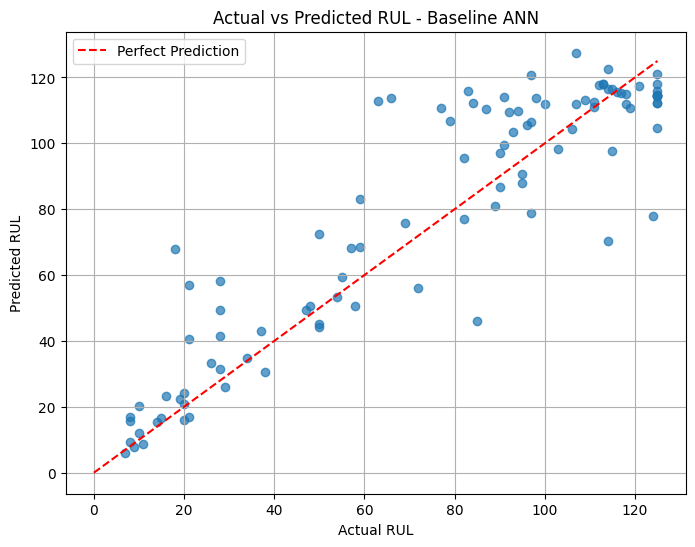

In [63]:


plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_final,
    y_test_pred_final,
    alpha=0.7
)

# Perfect prediction reference line
plt.plot([0, 125], [0, 125], 'r--', label="Perfect Prediction")

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("Actual vs Predicted RUL - Baseline ANN")
plt.legend()
plt.grid(True)
plt.show()

In [64]:
errors = y_test_final - y_test_pred_final

print("Mean Error:", round(errors.mean(), 2))
print("Median Error:", round(np.median(errors), 2))
print("Overestimations:", (errors < 0).sum())
print("Underestimations:", (errors > 0).sum())
print("Errors above 20 cycles:", (np.abs(errors) > 20).sum())
print("Maximum Absolute Error:", round(np.abs(errors).max(), 2))

Mean Error: -3.91
Median Error: -2.26
Overestimations: 58
Underestimations: 42
Errors above 20 cycles: 20
Maximum Absolute Error: 49.85


In [65]:
import pandas as pd
import numpy as np

test_error_analysis = pd.DataFrame({
    "Actual_RUL": y_test_final,
    "Predicted_RUL": y_test_pred_final
})

test_error_analysis["Absolute_Error"] = (
    test_error_analysis["Actual_RUL"] -
    test_error_analysis["Predicted_RUL"]
).abs()

test_error_analysis["RUL_Range"] = pd.cut(
    test_error_analysis["Actual_RUL"],
    bins=[-1, 25, 50, 75, 100, 125],
    labels=["0-25", "26-50", "51-75", "76-100", "101-125"]
)

range_performance = test_error_analysis.groupby(
    "RUL_Range",
    observed=False
).agg(
    Engines=("Actual_RUL", "count"),
    MAE=("Absolute_Error", "mean")
).round(2)

print(range_performance)

           Engines    MAE
RUL_Range                
0-25            19   8.79
26-50           14   9.33
51-75           10  17.74
76-100          24  16.54
101-125         33   9.53


In [66]:
test_error_analysis["Error"] = (
    test_error_analysis["Actual_RUL"] -
    test_error_analysis["Predicted_RUL"]
)

direction_analysis = test_error_analysis.groupby(
    "RUL_Range",
    observed=False
).agg(
    Overestimations=("Error", lambda x: (x < 0).sum()),
    Underestimations=("Error", lambda x: (x > 0).sum()),
    Mean_Error=("Error", "mean")
).round(2)

print(direction_analysis)

           Overestimations  Underestimations  Mean_Error
RUL_Range                                               
0-25                    14                 5       -7.47
26-50                   10                 4       -6.31
51-75                    7                 3      -12.92
76-100                  17                 7       -9.48
101-125                 10                23        5.94


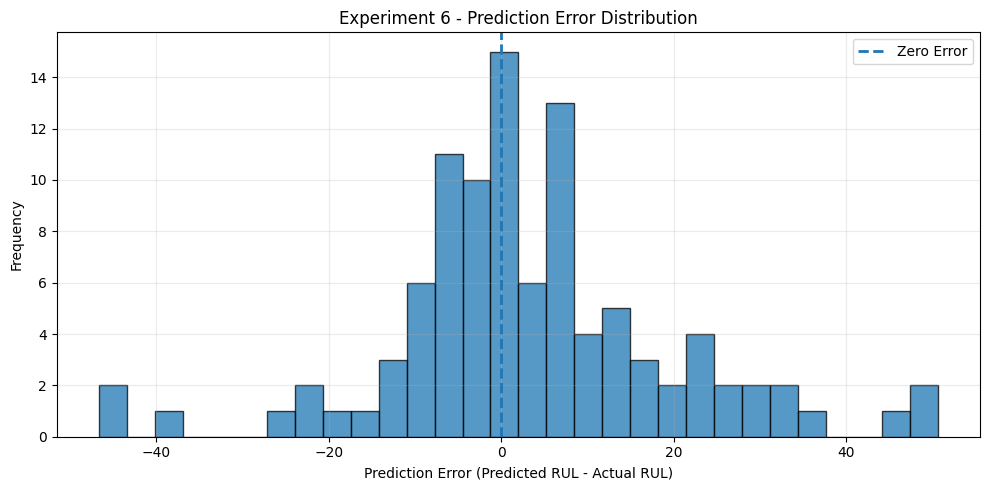

Mean Prediction Error: 3.424
Standard Deviation: 16.7107
Minimum Error: -46.6819
Maximum Error: 50.6871


In [ ]:

# Calculate prediction errors
prediction_errors = (
    np.asarray(y_test_pred_exp6).flatten()
    - np.asarray(y_test_final).flatten()
)

# Plot error distribution
plt.figure(figsize=(10, 5))

plt.hist(
    prediction_errors,
    bins=30,
    edgecolor="black",
    alpha=0.75
)

plt.axvline(
    0,
    linestyle="--",
    linewidth=2,
    label="Zero Error"
)

plt.title("Experiment 6 - Prediction Error Distribution")
plt.xlabel("Prediction Error (Predicted RUL - Actual RUL)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

print("Mean Prediction Error:", round(np.mean(prediction_errors), 4))
print("Standard Deviation:", round(np.std(prediction_errors), 4))
print("Minimum Error:", round(np.min(prediction_errors), 4))
print("Maximum Error:", round(np.max(prediction_errors), 4))


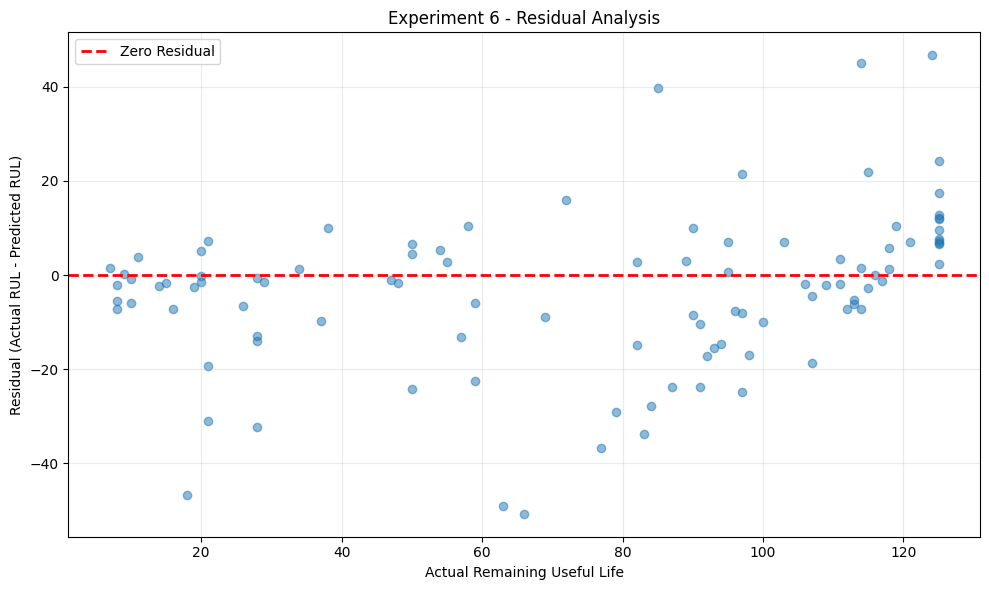

In [ ]:

# Prepare actual values and residuals
actual_rul = np.asarray(y_test_final).flatten()

residuals = (
    actual_rul
    - np.asarray(y_test_pred_exp6).flatten()
)

# Residual plot
plt.figure(figsize=(10, 6))

plt.scatter(
    actual_rul,
    residuals,
    alpha=0.5
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Zero Residual"
)

plt.title("Experiment 6 - Residual Analysis")
plt.xlabel("Actual Remaining Useful Life")
plt.ylabel("Residual (Actual RUL - Predicted RUL)")

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()



In [69]:



actual_rul = np.asarray(y_test_final).flatten()
predicted_rul = np.asarray(y_test_pred_exp6).flatten()

errors = predicted_rul - actual_rul
residuals = actual_rul - predicted_rul

print("PREDICTION ERROR ANALYSIS")
print("=" * 40)

print("Mean Error:", round(np.mean(errors), 4))
print("Mean Absolute Error:", round(np.mean(np.abs(errors)), 4))
print("Error Standard Deviation:", round(np.std(errors), 4))

print("\nERROR DISTRIBUTION")
print("=" * 40)

print("Underpredictions:", np.sum(errors < 0))
print("Overpredictions:", np.sum(errors > 0))
print("Exact Predictions:", np.sum(errors == 0))

print("\nRESIDUAL ANALYSIS")
print("=" * 40)

print("Mean Residual:", round(np.mean(residuals), 4))
print("Residual Median:", round(np.median(residuals), 4))
print("Residual 25th Percentile:", round(np.percentile(residuals, 25), 4))
print("Residual 75th Percentile:", round(np.percentile(residuals, 75), 4))


PREDICTION ERROR ANALYSIS
Mean Error: 3.424
Mean Absolute Error: 11.9878
Error Standard Deviation: 16.7107

ERROR DISTRIBUTION
Underpredictions: 42
Overpredictions: 58
Exact Predictions: 0

RESIDUAL ANALYSIS
Mean Residual: -3.424
Residual Median: -1.6686
Residual 25th Percentile: -10.0346
Residual 75th Percentile: 6.0422
